# # 03 · Two-sample tests and ANOVA (M3)
#
# **Research questions**
# 1. *Two groups:* Is mean PM2.5 different between two cities (Kolkata vs Cuttack)? Between winter and the
#    monsoon? Between weekdays and weekends?
# 2. *Three or more groups:* Does mean PM2.5 differ across states and across seasons? Is there a
#    state × season interaction?
#
# Following M2's normality results, tests are run on **log PM2.5**; differences on the log scale are
# reported back as **ratios of geometric means**. Every parametric test has a non-parametric check.
# Significance level α = 0.05 throughout.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from IPython.display import display

from src.style import apply_style, save_fig, save_table, STATE_COLORS, SEASON_COLORS, LABELS, ACCENT, FIGSIZE
from src.data import load_clean, STATE_ORDER, SEASON_ORDER

apply_style()
pd.set_option("display.width", 160, "display.max_columns", 30)
df = load_clean()

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

# ## Helper functions: Welch t-test with CI and effect sizes, Games-Howell post-hoc

In [2]:
def two_sample_report(a, b, label_a, label_b, log=True):
    """Welch t-test on log values (+ CI as ratio of geometric means), Levene, Cohen's d, Mann-Whitney."""
    xa, xb = (np.log(a), np.log(b)) if log else (np.asarray(a), np.asarray(b))
    na, nb = len(xa), len(xb)
    va, vb = xa.var(ddof=1), xb.var(ddof=1)
    diff = xa.mean() - xb.mean()
    se = np.sqrt(va / na + vb / nb)
    dfw = (va / na + vb / nb) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    t = diff / se
    p = 2 * stats.t.sf(abs(t), dfw)
    lo, hi = diff + np.array([-1, 1]) * stats.t.ppf(.975, dfw) * se
    sp = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2))
    d = diff / sp
    lev = stats.levene(xa, xb, center="median")
    t_student = stats.ttest_ind(xa, xb, equal_var=True)
    mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - 2 * mw.statistic / (na * nb)  # rank-biserial correlation
    sw_a, sw_b = stats.shapiro(xa).pvalue, stats.shapiro(xb).pvalue
    res = {
        "comparison": f"{label_a} vs {label_b}",
        f"n_{'A'}": na, "n_B": nb,
        "mean_A (µg/m³)": np.mean(a), "mean_B (µg/m³)": np.mean(b),
        "geo_mean_A": np.exp(xa.mean()) if log else np.nan, "geo_mean_B": np.exp(xb.mean()) if log else np.nan,
        "Shapiro p (A, B, log)": f"{fmt_p(sw_a)}, {fmt_p(sw_b)}",
        "Levene W": lev.statistic, "Levene p": fmt_p(lev.pvalue),
        "Student t (equal var)": t_student.statistic,
        "Welch t": t, "Welch df": dfw, "Welch p": fmt_p(p),
        "diff of log means": diff, "95% CI (log)": f"[{lo:.3f}, {hi:.3f}]",
        "ratio of geo means": np.exp(diff), "95% CI ratio": f"[{np.exp(lo):.2f}, {np.exp(hi):.2f}]",
        "Cohen's d (log)": d,
        "Mann-Whitney U": mw.statistic, "MW p": fmt_p(mw.pvalue), "rank-biserial r": r_rb,
    }
    return pd.Series(res)

def games_howell(data, group, value):
    g = data.groupby(group, observed=True)[value]
    m, v, n = g.mean(), g.var(ddof=1), g.size()
    k = len(m)
    rows = []
    for a, b in itertools.combinations(m.index, 2):
        se = np.sqrt(v[a] / n[a] + v[b] / n[b])
        dfw = (v[a] / n[a] + v[b] / n[b]) ** 2 / ((v[a] / n[a]) ** 2 / (n[a] - 1) + (v[b] / n[b]) ** 2 / (n[b] - 1))
        diff = m[a] - m[b]
        q = abs(diff) / se * np.sqrt(2)
        p = stats.studentized_range.sf(q, k, dfw)
        crit = stats.studentized_range.ppf(.95, k, dfw) / np.sqrt(2)
        rows.append({"group1": a, "group2": b, "diff (log)": diff, "ratio": np.exp(diff),
                     "CI low": np.exp(diff - crit * se), "CI high": np.exp(diff + crit * se),
                     "df": dfw, "p_adj": p, "reject": p < .05})
    return pd.DataFrame(rows)

def eta_omega(model_anova, effect):
    ss_eff = model_anova.loc[effect, "sum_sq"]
    ss_res = model_anova.loc["Residual", "sum_sq"]
    ss_tot = model_anova["sum_sq"].sum()
    df_eff = model_anova.loc[effect, "df"]
    ms_res = ss_res / model_anova.loc["Residual", "df"]
    return {"eta_sq": ss_eff / ss_tot, "partial_eta_sq": ss_eff / (ss_eff + ss_res),
            "omega_sq": (ss_eff - df_eff * ms_res) / (ss_tot + ms_res)}

# ## 1. Two-sample test A: Kolkata (West Bengal) vs Cuttack (Odisha)
#
# The two cities with the most sampling days in different states (Kolkata 4 stations, Cuttack 3).
# **Independence:** stations in the same city on the same day share weather, so we first average across
# stations to one value per **city-day** — each observation is then a different day (≈ 3–4 days apart).
#
# - H0: μ(log PM2.5, Kolkata) = μ(log PM2.5, Cuttack)
# - H1: the means differ (two-sided), α = 0.05

In [3]:
cityday = df.groupby(["city", "date"]).PM25.mean().reset_index()
kol = cityday.loc[cityday.city == "KOLKATA", "PM25"].values
cut = cityday.loc[cityday.city == "CUTTACK", "PM25"].values
testA = two_sample_report(kol, cut, "Kolkata", "Cuttack")
display(testA.to_frame("value"))

,value
comparison,Kolkata vs Cuttack
n_A,289
n_B,272
mean_A (µg/m³),56.566609
mean_B (µg/m³),35.027574
geo_mean_A,47.902895
geo_mean_B,33.184918
"Shapiro p (A, B, log)","< 0.001, < 0.001"
Levene W,112.379301
Levene p,< 0.001


# **Reading:** Levene's test shows whether the variances differ; Welch's t-test does not assume equal
# variances, so it is our default. The ratio of geometric means says how many times higher Kolkata's
# typical PM2.5 is than Cuttack's, with a 95% CI. Cohen's d on the log scale gives the effect size
# (0.2 small, 0.5 medium, 0.8 large). Mann-Whitney U confirms the result without the normality assumption.

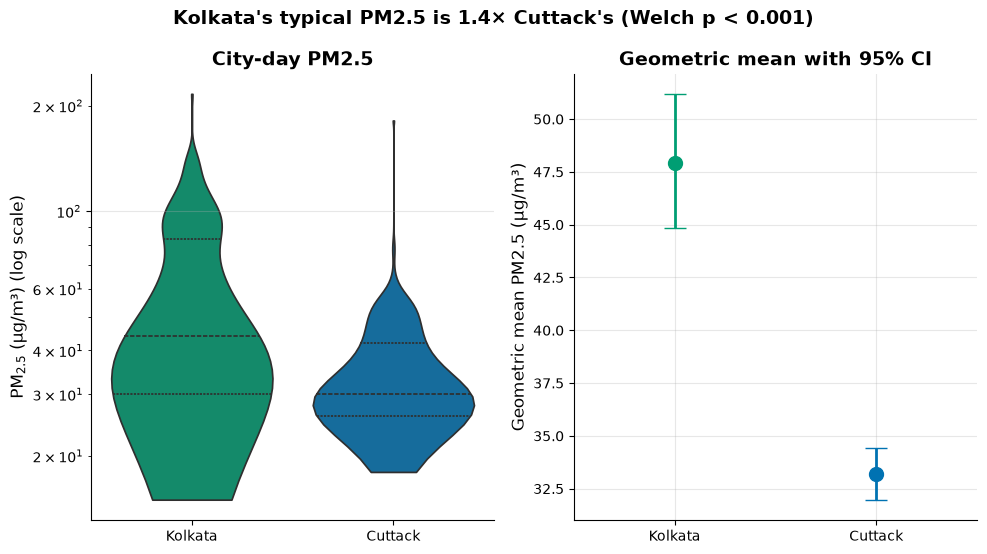

In [4]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
plot_df = cityday[cityday.city.isin(["KOLKATA", "CUTTACK"])].copy()
plot_df["city"] = plot_df.city.str.title()
pal = {"Kolkata": STATE_COLORS["West Bengal"], "Cuttack": STATE_COLORS["Odisha"]}
sns.violinplot(data=plot_df, x="city", y="PM25", order=["Kolkata", "Cuttack"], hue="city", palette=pal, inner="quartile", cut=0, ax=axes[0], legend=False)
axes[0].set_yscale("log"); axes[0].set_ylabel(LABELS["PM25"] + " (log scale)"); axes[0].set_xlabel("")
axes[0].set_title("City-day PM2.5")
gm = plot_df.groupby("city").PM25.apply(lambda x: np.exp(np.log(x).mean()))
ci_lo = plot_df.groupby("city").PM25.apply(lambda x: np.exp(np.log(x).mean() - 1.96 * np.log(x).std() / np.sqrt(len(x))))
ci_hi = plot_df.groupby("city").PM25.apply(lambda x: np.exp(np.log(x).mean() + 1.96 * np.log(x).std() / np.sqrt(len(x))))
for i, c in enumerate(["Kolkata", "Cuttack"]):
    axes[1].errorbar(i, gm[c], yerr=[[gm[c] - ci_lo[c]], [ci_hi[c] - gm[c]]], fmt="o", ms=10, capsize=8, color=pal[c], lw=2)
axes[1].set_xticks([0, 1], ["Kolkata", "Cuttack"]); axes[1].set_xlim(-.5, 1.5)
axes[1].set_ylabel("Geometric mean PM2.5 (µg/m³)"); axes[1].set_title("Geometric mean with 95% CI")
fig.suptitle(f"Kolkata's typical PM2.5 is {testA['ratio of geo means']:.1f}× Cuttack's (Welch p {testA['Welch p']})",
             fontweight="bold", fontsize=14)
fig.tight_layout(); save_fig(fig, "m3_two_sample_kolkata_cuttack"); plt.show()

# ## 2. Two-sample test B: winter vs monsoon (paired by station)
#
# The same stations are measured in both seasons, so the two samples are **not independent**. We average
# log PM2.5 per station per season and use a **paired t-test** on the stations that have both seasons, with
# the **Wilcoxon signed-rank** test as the non-parametric check.
#
# - H0: mean within-station difference (winter − monsoon) in log PM2.5 = 0
# - H1: ≠ 0

In [5]:
st_season = df.groupby(["station", "state", "season"], observed=True).log_PM25.mean().unstack("season")
paired = st_season[["Winter", "Monsoon"]].dropna()
d = paired["Winter"] - paired["Monsoon"]
pt = stats.ttest_rel(paired["Winter"], paired["Monsoon"])
ci = pt.confidence_interval()
wil = stats.wilcoxon(paired["Winter"], paired["Monsoon"])
testB = pd.Series({
    "comparison": "Winter vs Monsoon (paired by station)", "n stations": len(paired),
    "Shapiro p of differences": fmt_p(stats.shapiro(d).pvalue),
    "mean diff (log)": d.mean(), "paired t": pt.statistic, "df": pt.df, "p": fmt_p(pt.pvalue),
    "ratio winter/monsoon": np.exp(d.mean()),
    "95% CI ratio": f"[{np.exp(ci.low):.2f}, {np.exp(ci.high):.2f}]",
    "Cohen's dz": d.mean() / d.std(ddof=1),
    "Wilcoxon W": wil.statistic, "Wilcoxon p": fmt_p(wil.pvalue),
    "stations higher in winter": f"{(d > 0).sum()} of {len(d)}",
})
display(testB.to_frame("value"))

,value
comparison,Winter vs Monsoon (paired by station)
n stations,39
Shapiro p of differences,0.037
mean diff (log),0.465666
paired t,7.03495
df,38
p,< 0.001
ratio winter/monsoon,1.593075
95% CI ratio,"[1.39, 1.82]"
Cohen's dz,1.126494


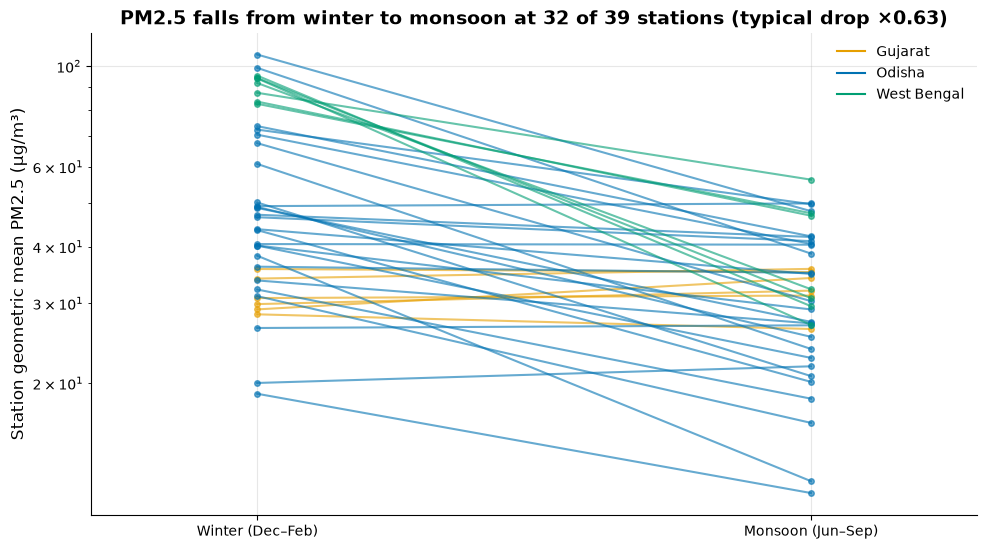

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for (st, state), row in paired.iterrows():
    ax.plot([0, 1], np.exp(row[["Winter", "Monsoon"]].values), color=STATE_COLORS[state], alpha=.6, marker="o", ms=4)
for s in STATE_ORDER:
    ax.plot([], [], color=STATE_COLORS[s], label=s)
ax.set_xticks([0, 1], ["Winter (Dec–Feb)", "Monsoon (Jun–Sep)"]); ax.set_xlim(-.3, 1.3)
ax.set_yscale("log"); ax.set_ylabel("Station geometric mean PM2.5 (µg/m³)")
ax.set_title(f"PM2.5 falls from winter to monsoon at {(d > 0).sum()} of {len(d)} stations "
             f"(typical drop ×{1/np.exp(d.mean()):.2f})")
ax.legend(); fig.tight_layout(); save_fig(fig, "m3_paired_winter_monsoon"); plt.show()

# ## 3. Two-sample test C: weekday vs weekend
# Station-days, Welch t on log PM2.5. (Sampling is mostly on weekdays: only ~9% of rows are weekends.)

In [7]:
wk = df.loc[df.weekday, "PM25"].values
we = df.loc[~df.weekday, "PM25"].values
testC = two_sample_report(wk, we, "Weekday", "Weekend")
display(testC.to_frame("value"))

,value
comparison,Weekday vs Weekend
n_A,3434
n_B,344
mean_A (µg/m³),42.543098
mean_B (µg/m³),47.656977
geo_mean_A,37.370485
geo_mean_B,42.306384
"Shapiro p (A, B, log)","< 0.001, 0.002"
Levene W,2.076887
Levene p,0.150


In [8]:
two_sample = pd.concat([testA, testC], axis=1).T
save_table(two_sample, "m3_two_sample_tests")
save_table(testB.to_frame("value"), "m3_paired_winter_monsoon", index=True)

WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m3_paired_winter_monsoon.csv')

# ## 4. One-way ANOVA: log PM2.5 across the three states
#
# - H0: μ_Gujarat = μ_Odisha = μ_WestBengal (log PM2.5); H1: at least one mean differs.
# - Assumptions: normality of residuals (Q-Q, Shapiro on a sample), homogeneity of variance (Levene).
# - If Levene rejects → **Welch ANOVA**; if residuals are clearly non-normal → **Kruskal-Wallis** as well.
# - Post-hoc: **Tukey HSD** and **Games-Howell** (which does not assume equal variances).
# - Effect size: η² and ω².
#
# *Robustness:* station-days from the same station are not fully independent, so we repeat the ANOVA on
# **station annual means** (n = 71 stations).

In [9]:
def oneway_block(data, group, value, order, name):
    groups = [data.loc[data[group] == g, value].values for g in order]
    desc = data.groupby(group, observed=True)[value].agg(n="size", mean="mean", sd="std").reindex(order)
    desc["geo_mean (µg/m³)"] = np.exp(desc["mean"])
    lev = stats.levene(*groups, center="median")
    f = stats.f_oneway(*groups)
    welch = anova_oneway(groups, use_var="unequal")
    kw = stats.kruskal(*groups)
    model = smf.ols(f"{value} ~ C({group})", data=data).fit()
    aov = sm.stats.anova_lm(model, typ=2)
    eff = eta_omega(aov, f"C({group})")
    resid_sw = stats.shapiro(model.resid.sample(min(len(model.resid), 500), random_state=42)).pvalue
    N, k = len(data), len(order)
    eps2 = (kw.statistic - k + 1) / (N - k)
    summary = pd.Series({
        "analysis": name, "N": N, "groups": k,
        "Levene W": lev.statistic, "Levene p": fmt_p(lev.pvalue),
        "Shapiro p (residuals, n≤500)": fmt_p(resid_sw),
        "F": f.statistic, "df": f"{k-1}, {N-k}", "ANOVA p": fmt_p(f.pvalue),
        "Welch F": welch.statistic, "Welch df": f"{welch.df_num:.0f}, {welch.df_denom:.1f}", "Welch p": fmt_p(welch.pvalue),
        "Kruskal H": kw.statistic, "Kruskal p": fmt_p(kw.pvalue), "epsilon² (KW)": eps2,
        "eta²": eff["eta_sq"], "omega²": eff["omega_sq"],
    })
    return desc, summary, model

desc_state, aov_state, m_state = oneway_block(df, "state", "log_PM25", STATE_ORDER, "State (station-days)")
display(desc_state.round(3)); display(aov_state.to_frame("value"))

,n,mean,sd,geo_mean (µg/m³)
state,,,,
Gujarat,1080,3.420,0.188,30.564
Odisha,2060,3.616,0.522,37.176
West Bengal,638,4.045,0.523,57.107


,value
analysis,State (station-days)
N,3778
groups,3
Levene W,314.410247
Levene p,< 0.001
"Shapiro p (residuals, n≤500)",< 0.001
F,385.718067
df,"2, 3775"
ANOVA p,< 0.001
Welch F,494.283251


In [10]:
tukey_state = pairwise_tukeyhsd(df.log_PM25, df.state)
print(tukey_state.summary())
gh_state = games_howell(df, "state", "log_PM25")
display(gh_state.round(4))

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1    group2   meandiff p-adj lower  upper  reject
-------------------------------------------------------
Gujarat      Odisha   0.1959   0.0  0.156 0.2357   True
Gujarat West Bengal   0.6251   0.0 0.5721 0.6781   True
 Odisha West Bengal   0.4293   0.0 0.3812 0.4773   True
-------------------------------------------------------


,group1,group2,diff (log),ratio,CI low,CI high,df,p_adj,reject
0,Gujarat,Odisha,-0.1959,0.8221,0.7977,0.8473,2869.8523,0.0,True
1,Gujarat,West Bengal,-0.6251,0.5352,0.5089,0.5629,735.7716,0.0,True
2,Odisha,West Bengal,-0.4293,0.6510,0.6158,0.6882,1060.1291,0.0,True


In [11]:
stmeans = df.groupby(["station", "state"]).log_PM25.mean().reset_index()
desc_st, aov_st, _ = oneway_block(stmeans, "state", "log_PM25", STATE_ORDER, "State (station annual means)")
display(desc_st.round(3)); display(aov_st.to_frame("value"))
gh_st = games_howell(stmeans, "state", "log_PM25")
display(gh_st.round(4))

,n,mean,sd,geo_mean (µg/m³)
state,,,,
Gujarat,32,3.405,0.087,30.100
Odisha,32,3.575,0.410,35.687
West Bengal,7,4.011,0.213,55.194


,value
analysis,State (station annual means)
N,71
groups,3
Levene W,20.618898
Levene p,< 0.001
"Shapiro p (residuals, n≤500)",0.013
F,12.971638
df,"2, 68"
ANOVA p,< 0.001
Welch F,28.153526


,group1,group2,diff (log),ratio,CI low,CI high,df,p_adj,reject
0,Gujarat,Odisha,-0.1702,0.8435,0.7035,1.0113,33.8230,0.0695,False
1,Gujarat,West Bengal,-0.6063,0.5453,0.4264,0.6975,6.4508,0.0005,True
2,Odisha,West Bengal,-0.4361,0.6466,0.4902,0.8528,17.4625,0.0023,True


# ## 5. One-way ANOVA: log PM2.5 across seasons

In [12]:
desc_season, aov_season, m_season = oneway_block(df, "season", "log_PM25", SEASON_ORDER, "Season (station-days)")
display(desc_season.round(3)); display(aov_season.to_frame("value"))
gh_season = games_howell(df, "season", "log_PM25")
display(gh_season.round(4))
tukey_season = pairwise_tukeyhsd(df.log_PM25, df.season.astype(str))
print(tukey_season.summary())

,n,mean,sd,geo_mean (µg/m³)
season,,,,
Winter,1197,3.740,0.514,42.085
Summer,883,3.585,0.446,36.054
Monsoon,1086,3.453,0.422,31.585
Post-monsoon,612,3.808,0.538,45.078


,value
analysis,Season (station-days)
N,3778
groups,4
Levene W,20.576493
Levene p,< 0.001
"Shapiro p (residuals, n≤500)",0.008
F,101.956552
df,"3, 3774"
ANOVA p,< 0.001
Welch F,104.265677


,group1,group2,diff (log),ratio,CI low,CI high,df,p_adj,reject
0,Winter,Summer,0.1547,1.1673,1.1056,1.2324,2023.7563,0.0000,True
1,Winter,Monsoon,0.2870,1.3324,1.2669,1.4013,2258.9598,0.0000,True
2,Winter,Post-monsoon,-0.0687,0.9336,0.8724,0.9991,1182.0215,0.0455,True
3,Summer,Monsoon,0.1323,1.1415,1.0850,1.2009,1840.2822,0.0000,True
4,Summer,Post-monsoon,-0.2234,0.7998,0.7472,0.8561,1150.6377,0.0000,True
5,Monsoon,Post-monsoon,-0.3557,0.7007,0.6566,0.7477,1037.4373,0.0000,True


      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
   group1       group2    meandiff p-adj  lower   upper  reject
---------------------------------------------------------------
     Monsoon Post-monsoon   0.3557   0.0  0.2936  0.4178   True
     Monsoon       Summer   0.1323   0.0  0.0767   0.188   True
     Monsoon       Winter    0.287   0.0  0.2356  0.3385   True
Post-monsoon       Summer  -0.2234   0.0 -0.2879 -0.1588   True
Post-monsoon       Winter  -0.0687  0.02 -0.1297 -0.0077   True
      Summer       Winter   0.1547   0.0  0.1002  0.2091   True
---------------------------------------------------------------


In [13]:
anova_table = pd.concat([aov_state, aov_st, aov_season], axis=1).T
save_table(anova_table, "m3_oneway_anova")
posthoc = pd.concat([gh_state.assign(analysis="State (station-days)"),
                     gh_st.assign(analysis="State (station means)"),
                     gh_season.assign(analysis="Season (station-days)")])
save_table(posthoc, "m3_games_howell_posthoc")

WindowsPath('C:/Users/Advay/Desktop/ASM/Asm project/results/m3_games_howell_posthoc.csv')

# ### Residual diagnostics for the state ANOVA

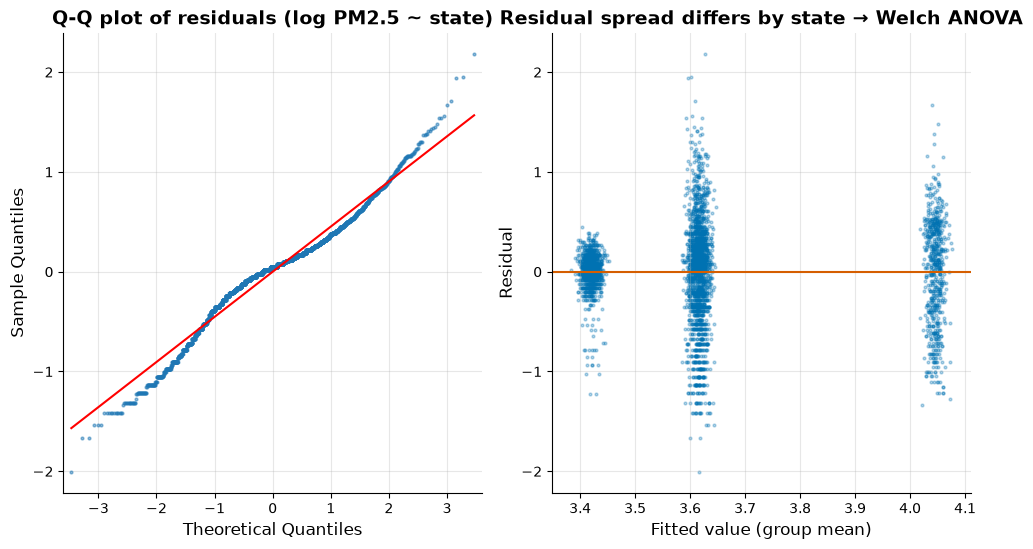

In [14]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
sm.qqplot(m_state.resid, line="s", ax=axes[0], markersize=2, alpha=.5)
axes[0].set_title("Q-Q plot of residuals (log PM2.5 ~ state)")
axes[1].scatter(m_state.fittedvalues + np.random.default_rng(42).normal(0, .01, len(m_state.resid)),
                m_state.resid, s=4, alpha=.3, color="#0072B2")
axes[1].axhline(0, color=ACCENT); axes[1].set_xlabel("Fitted value (group mean)"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residual spread differs by state → Welch ANOVA")
fig.tight_layout(); save_fig(fig, "m3_anova_residuals"); plt.show()

# ## 6. Two-way ANOVA: state × season
#
# log PM2.5 ~ state + season + state:season, Type II sums of squares (the design is unbalanced).
# Partial η² for each effect. An interaction means the seasonal swing is not the same in every state.

In [15]:
m2 = smf.ols("log_PM25 ~ C(state) * C(season)", data=df).fit()
aov2 = sm.stats.anova_lm(m2, typ=2)
for eff in ["C(state)", "C(season)", "C(state):C(season)"]:
    e = eta_omega(aov2, eff)
    aov2.loc[eff, "partial_eta_sq"] = e["partial_eta_sq"]
display(aov2.round(4))
save_table(aov2.round(5), "m3_twoway_anova", index=True)
print(f"R² of two-way model: {m2.rsquared:.3f}")

,sum_sq,df,F,PR(>F),partial_eta_sq
C(state),192.9118,2.0,613.5720,0.0,0.2458
C(season),104.7480,3.0,222.1065,0.0,0.1503
C(state):C(season),76.1617,6.0,80.7462,0.0,0.1140
Residual,592.0298,3766.0,NaN,NaN,NaN


R² of two-way model: 0.364


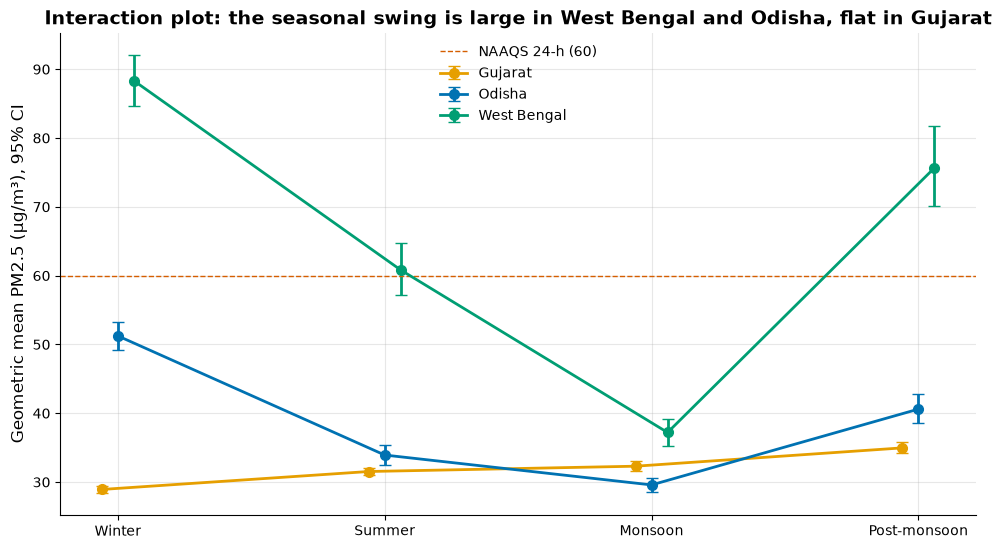

In [16]:
cell = df.groupby(["state", "season"], observed=True).log_PM25.agg(["mean", "std", "size"]).reset_index()
cell["gm"] = np.exp(cell["mean"])
cell["lo"] = np.exp(cell["mean"] - 1.96 * cell["std"] / np.sqrt(cell["size"]))
cell["hi"] = np.exp(cell["mean"] + 1.96 * cell["std"] / np.sqrt(cell["size"]))
fig, ax = plt.subplots(figsize=FIGSIZE)
x = np.arange(len(SEASON_ORDER))
for i, s in enumerate(STATE_ORDER):
    c = cell[cell.state == s].set_index("season").reindex(SEASON_ORDER)
    ax.errorbar(x + (i - 1) * .06, c.gm, yerr=[c.gm - c.lo, c.hi - c.gm], marker="o", ms=7, capsize=4,
                lw=2, color=STATE_COLORS[s], label=s)
ax.axhline(60, color=ACCENT, ls="--", lw=1, label="NAAQS 24-h (60)")
ax.set_xticks(x, SEASON_ORDER); ax.set_ylabel("Geometric mean PM2.5 (µg/m³), 95% CI")
ax.set_title("Interaction plot: the seasonal swing is large in West Bengal and Odisha, flat in Gujarat")
ax.legend(); fig.tight_layout(); save_fig(fig, "m3_interaction_state_season"); plt.show()

# ## 7. Conclusions (slides 7–8)
#
# **Two-sample A – Kolkata vs Cuttack (city-days, n = 289 vs 272).** Levene rejects equal variances
# (p < 0.001), so Welch's test is the right choice. Welch t = 9.46, df = 448, p < 0.001. Kolkata's
# geometric-mean PM2.5 is **1.44× Cuttack's (95% CI 1.34–1.56)**, i.e. 48 vs 33 µg/m³; Cohen's d = 0.79
# (medium-to-large). Mann-Whitney agrees (p < 0.001, rank-biserial r = 0.38). Reject H0.
#
# **Two-sample B – winter vs monsoon (paired, 39 stations).** PM2.5 is higher in winter at 32 of 39
# stations; winter is **1.59× the monsoon level (95% CI 1.39–1.82)**, paired t(38) = 7.03, p < 0.001,
# d_z = 1.13 (large). Wilcoxon signed-rank agrees (p < 0.001).
#
# **Two-sample C – weekday vs weekend.** Weekend PM2.5 is slightly *higher* (ratio 0.88, CI 0.84–0.93,
# d = −0.25, small). Only 9% of samples fall on weekends and they come from particular stations, so this
# is most likely a sampling-schedule artefact, not a real "weekend effect". We do not over-interpret it.
#
# **One-way ANOVA – states.** Variances differ (Levene p < 0.001), so Welch ANOVA: F(2, 1507) = 494,
# p < 0.001; Kruskal-Wallis H = 698, p < 0.001. Effect size η² = 0.17 (ω² = 0.17): state explains about
# 17% of the variation in log PM2.5. Games-Howell: all three pairs differ; West Bengal's typical PM2.5 is
# 1.87× Gujarat's and 1.54× Odisha's. **Robustness on 71 station means:** Welch F(2, 14.4) = 28.2,
# p < 0.001, η² = 0.28; West Bengal still differs from both, but **Gujarat vs Odisha is no longer
# significant (p = 0.07)**: that difference depends on treating station-days as independent.
#
# **One-way ANOVA – seasons.** Welch F(3, 1839) = 104, p < 0.001, η² = 0.075. All pairs differ
# (Games-Howell); order: Post-monsoon ≥ Winter > Summer > Monsoon. Winter is 1.33× the monsoon level.
#
# **Two-way ANOVA – state × season.** State (partial η² = 0.25), season (0.15) and their interaction (0.11)
# are all significant (p < 0.001); the model explains 36% of the variance. The interaction means the
# seasonal swing is large in West Bengal and Odisha and almost absent in Gujarat.
#
# **Caveat:** with thousands of observations even small effects are "significant", so we lead with ratios,
# CIs and effect sizes, not p-values.